In [3]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("../data/raw/bank-additional-full.csv",sep=";")
print(df.head())
df.describe()

   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  ...  campaign  pdays  previous     poutcome emp.var.rate  \
0   may         mon  ...         1    999         0  nonexistent          1.1   
1   may         mon  ...         1    999         0  nonexistent          1.1   
2   may         mon  ...         1    999         0  nonexistent          1.1   
3   may         mon  ...         1    999         0  nonexistent          1.1   
4   may         mon  ...         1    999         0  nonexistent          1.1   

   cons.price.idx  cons.conf.idx  euribor3m  nr.employed

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [25]:
df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

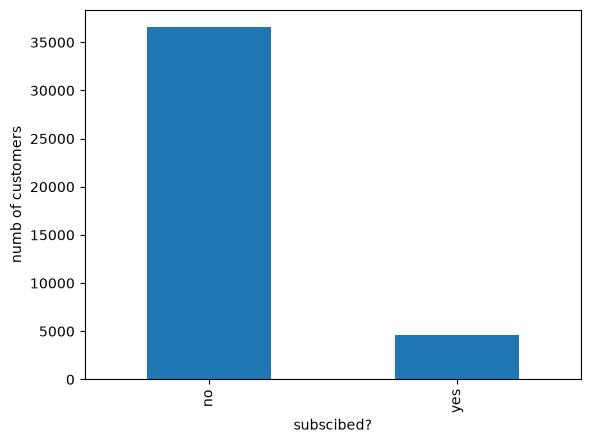

y
no     88.73
yes    11.27
Name: proportion, dtype: float64

In [ ]:
df["y"].value_counts().plot(
    kind="bar"
)
plt.xlabel("subscibed?")
plt.ylabel("numb of customers")
plt.show()
(df["y"].value_counts(normalize=True)*100).round(2)

In [27]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='str')

In [5]:
#zmienna docelowa y
#age,job,loan,deafult,housing,balance,poutcome,campain
par=df[['age','job','loan','default','housing','poutcome','campaign','y']].copy()

In [8]:
print(par.describe())
y=par["y"].copy()
X=par.drop("y",axis=1)
#y.shape
#X.shape

               age      campaign
count  41188.00000  41188.000000
mean      40.02406      2.567593
std       10.42125      2.770014
min       17.00000      1.000000
25%       32.00000      1.000000
50%       38.00000      2.000000
75%       47.00000      3.000000
max       98.00000     56.000000


In [30]:
import sklearn as skl
X.dtypes


age         int64
job           str
loan          str
default       str
housing       str
poutcome      str
campaign    int64
dtype: object

In [31]:
Encoded_X = pd.get_dummies(X,columns=['job','loan','default','housing','poutcome'],drop_first=True)
Encoded_X.dtypes

age                     int64
campaign                int64
job_blue-collar          bool
job_entrepreneur         bool
job_housemaid            bool
job_management           bool
job_retired              bool
job_self-employed        bool
job_services             bool
job_student              bool
job_technician           bool
job_unemployed           bool
job_unknown              bool
loan_unknown             bool
loan_yes                 bool
default_unknown          bool
default_yes              bool
housing_unknown          bool
housing_yes              bool
poutcome_nonexistent     bool
poutcome_success         bool
dtype: object

In [58]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
X_train, X_test, y_train, y_test = train_test_split(Encoded_X,y ,
                                   random_state=104, 
                                   test_size=0.20,
                                   stratify=y, 
                                   shuffle=True)
model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train,y_train)
y_pred=model_lr.predict(X_test)
accuracy_score(y_test,y_pred)
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
report = classification_report(y_test, y_pred, output_dict=True)['yes']
models = pd.DataFrame(columns=['model_lr','model_cl',"model_dt","model_lr_balanced",'model_cl_balanced'])
models['model_lr'] = { "prec":report['precision'],"f1":report['f1-score'],"recall":report['recall']}



              precision    recall  f1-score   support

          no       0.91      0.99      0.95      7310
         yes       0.68      0.21      0.32       928

    accuracy                           0.90      8238
   macro avg       0.80      0.60      0.63      8238
weighted avg       0.88      0.90      0.88      8238

[[7220   90]
 [ 734  194]]


In [62]:
from sklearn.tree import DecisionTreeClassifier
model_dt = DecisionTreeClassifier()
model_dt.fit(X_train,y_train)
y_pred_dt = model_dt.predict(X_test)
accuracy_score(y_test,y_pred_dt)
print(classification_report(y_test,y_pred_dt))
print(confusion_matrix(y_test,y_pred_dt))
d2 = classification_report(y_test,y_pred_dt)
report = classification_report(y_test, y_pred_dt, output_dict=True)['yes']
models['model_dt'] = { "prec":report['precision'],"f1":report['f1-score'],"recall":report['recall']}

              precision    recall  f1-score   support

          no       0.90      0.96      0.93      7310
         yes       0.37      0.18      0.24       928

    accuracy                           0.87      8238
   macro avg       0.63      0.57      0.58      8238
weighted avg       0.84      0.87      0.85      8238

[[7029  281]
 [ 765  163]]


In [63]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model_cl = RandomForestClassifier(n_estimators=100, random_state=42)
model_cl.fit(X_train_s, y_train)
y_pred = model_cl.predict(X_test_s)

accuracy_score(y_test,y_pred)
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
report = classification_report(y_test, y_pred, output_dict=True)['yes']
models['model_cl'] = { "prec":report['precision'],"f1":report['f1-score'],"recall":report['recall']}


              precision    recall  f1-score   support

          no       0.91      0.97      0.94      7310
         yes       0.47      0.20      0.28       928

    accuracy                           0.88      8238
   macro avg       0.69      0.59      0.61      8238
weighted avg       0.86      0.88      0.86      8238

[[7100  210]
 [ 743  185]]


In [61]:
model_cl = RandomForestClassifier(n_estimators=100, random_state=42,class_weight="balanced")
model_cl.fit(X_train_s, y_train)
y_pred = model_cl.predict(X_test_s)

accuracy_score(y_test,y_pred)
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

report = classification_report(y_test, y_pred, output_dict=True)['yes']
models['model_cl_balanced'] = { "prec":report['precision'],"f1":report['f1-score'],"recall":report['recall']}


              precision    recall  f1-score   support

          no       0.91      0.74      0.82      7310
         yes       0.18      0.46      0.26       928

    accuracy                           0.70      8238
   macro avg       0.55      0.60      0.54      8238
weighted avg       0.83      0.70      0.75      8238

[[5383 1927]
 [ 504  424]]


In [64]:
model_lr = LogisticRegression(max_iter=1000,class_weight="balanced")
model_lr.fit(X_train,y_train)
y_pred=model_lr.predict(X_test)
accuracy_score(y_test,y_pred)
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

report = classification_report(y_test, y_pred, output_dict=True)['yes']
models['model_lr_balanced'] = { "prec":report['precision'],"f1":report['f1-score'],"recall":report['recall']}


              precision    recall  f1-score   support

          no       0.92      0.77      0.84      7310
         yes       0.22      0.51      0.30       928

    accuracy                           0.74      8238
   macro avg       0.57      0.64      0.57      8238
weighted avg       0.84      0.74      0.78      8238

[[5613 1697]
 [ 458  470]]


In [65]:
models

,model_lr,model_cl,model_dt,model_lr_balanced,model_cl_balanced
prec,0.683099,0.468354,0.367117,0.216890,0.180349
f1,0.320132,0.279667,0.237609,0.303716,0.258615
recall,0.209052,0.199353,0.175647,0.506466,0.456897
